<a href="https://colab.research.google.com/github/mitadeon/tugas-machine-learning/blob/main/House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction — Pengolahan Data, Modeling, dan Evaluasi
## Panduan kode dan penjelasan proses

Notebook ini menjelaskan setiap tahapan secara berurutan. Dataset `train.csv` memiliki kolom target `SalePrice`, sedangkan `test.csv` tidak memiliki target. Karena itu, evaluasi dilakukan dengan membagi data train menjadi data training dan validasi.

**Tujuan:** membangun model regresi untuk memperkirakan harga rumah dari karakteristik rumah.


## 0. Import Library

Library adalah kumpulan fungsi siap pakai. Pada bagian ini kita memanggil library untuk manipulasi data, visualisasi, membagi data, membuat pipeline preprocessing/model, dan menghitung metrik evaluasi.

- `pandas`: membaca dan mengelola tabel.
- `numpy`: operasi numerik.
- `matplotlib` dan `seaborn`: membuat grafik.
- `scikit-learn`: preprocessing, model Machine Learning, serta evaluasi.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42


**Penjelasan kode:**
- `warnings.filterwarnings("ignore")` menyembunyikan peringatan yang tidak diperlukan agar output lebih rapi.
- `train_test_split` membagi dataset menjadi bagian training dan validasi.
- `ColumnTransformer` menerapkan proses berbeda untuk kolom numerik dan kategorikal.
- `Pipeline` menyusun preprocessing dan model menjadi satu alur.
- `SimpleImputer` mengisi nilai kosong.
- `OneHotEncoder` mengubah kategori teks menjadi fitur numerik.
- `LinearRegression`, `RandomForestRegressor`, dan `ExtraTreesRegressor` adalah tiga algoritma regresi yang dibandingkan.
- `MAE`, `RMSE`, dan `R²` digunakan untuk menilai hasil prediksi.
- `RANDOM_STATE = 42` menjaga pembagian data tetap sama saat notebook dijalankan ulang.


## 1. Data Loading — Memuat Dataset

Tahap pertama adalah membaca file CSV. `train.csv` dipakai untuk membangun dan mengevaluasi model. `test.csv` disediakan untuk prediksi akhir dan tidak memiliki nilai target.


In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
display(train.head())


Train shape: (1460, 81)
Test shape : (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**Penjelasan kode dan proses:**
- `pd.read_csv()` membaca file CSV menjadi DataFrame.
- `train.shape` dan `test.shape` menampilkan jumlah baris dan kolom.
- `head()` menampilkan lima baris pertama untuk melihat contoh struktur data.
- Pada dataset ini, `SalePrice` merupakan harga rumah yang ingin diprediksi.


## 2. Data Understanding — Memahami Data

Sebelum melakukan pemodelan, kita perlu memahami struktur, tipe data, rentang nilai, dan kelengkapan data.


In [3]:
train.info()
display(train.describe(include="all").T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.0,NaN,NaN,NaN,730.5,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,NaN,NaN,NaN,56.89726,42.300571,20.0,20.0,50.0,70.0,190.0
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.0,NaN,NaN,NaN,70.049958,24.284752,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,NaN,NaN,NaN,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.5,215245.0
...,...,...,...,...,...,...,...,...,...,...,...
MoSold,1460.0,NaN,NaN,NaN,6.321918,2.703626,1.0,5.0,6.0,8.0,12.0
YrSold,1460.0,NaN,NaN,NaN,2007.815753,1.328095,2006.0,2007.0,2008.0,2009.0,2010.0
SaleType,1460,9,WD,1267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SaleCondition,1460,6,Normal,1198,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Penjelasan:**
- `info()` menunjukkan nama kolom, jumlah nilai non-null, dan tipe data.
- `describe(include="all")` menghasilkan ringkasan statistik. Untuk numerik, ditampilkan rata-rata, standar deviasi, minimum, kuartil, dan maksimum. Untuk kategori, ditampilkan jumlah kategori dan kategori yang paling sering muncul.
- `.T` mengubah orientasi tabel agar setiap variabel tampil sebagai satu baris sehingga lebih mudah dibaca.


In [4]:
print("Jumlah duplikat:", train.duplicated().sum())

missing = train.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))


Jumlah duplikat: 0


,missing_count
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


**Penjelasan:**
- `duplicated()` menandai baris yang seluruh nilainya sama dengan baris sebelumnya.
- `sum()` menghitung jumlah baris duplikat.
- `isnull().sum()` menghitung banyaknya nilai kosong per kolom.
- `sort_values(ascending=False)` mengurutkan kolom dari nilai kosong terbanyak.
- Filter `missing > 0` hanya menampilkan kolom yang memang memiliki nilai kosong.

Nilai kosong tidak langsung dihapus karena beberapa kolom bisa memiliki banyak data yang hilang. Pada tahap preprocessing, nilai kosong akan diisi menggunakan strategi yang sesuai.


## 3. EDA — Exploratory Data Analysis

EDA adalah eksplorasi awal untuk melihat pola, distribusi, hubungan, dan kemungkinan karakteristik penting pada data. Grafik membantu memahami data sebelum memilih model.


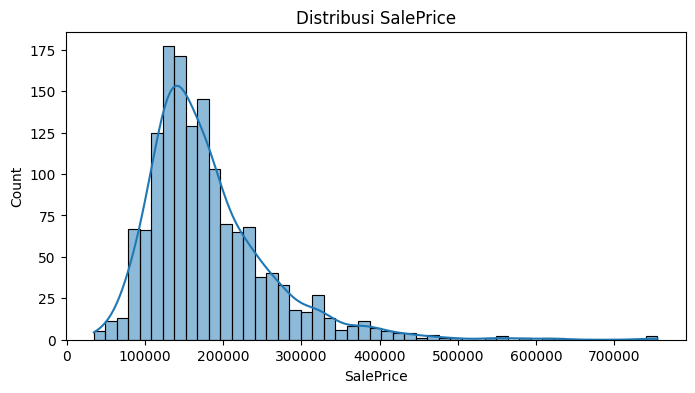

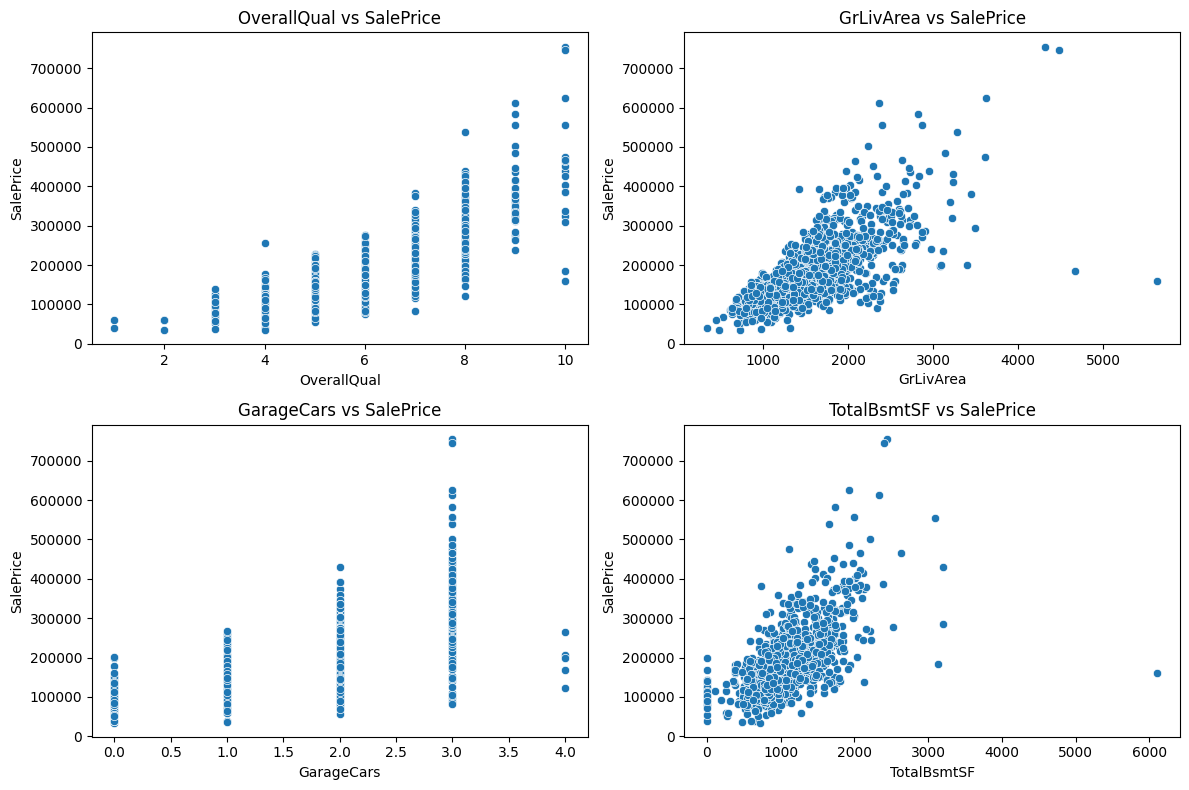

In [5]:
# Distribusi target harga rumah
plt.figure(figsize=(8, 4))
sns.histplot(train["SalePrice"], kde=True)
plt.title("Distribusi SalePrice")
plt.xlabel("SalePrice")
plt.show()

# Hubungan fitur numerik dengan harga
selected = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(selected, axes.flat):
    sns.scatterplot(data=train, x=feature, y="SalePrice", ax=ax)
    ax.set_title(f"{feature} vs SalePrice")
plt.tight_layout()
plt.show()


**Penjelasan:**
- `histplot()` memperlihatkan sebaran harga rumah; `kde=True` menambahkan kurva kepadatan.
- `figsize` mengatur ukuran gambar.
- `subplots(2, 2)` membuat empat area grafik dalam susunan 2×2.
- `scatterplot()` memperlihatkan hubungan antara satu fitur dengan `SalePrice`.
- `OverallQual` adalah penilaian kualitas rumah; `GrLivArea` adalah luas area hunian di atas tanah; `GarageCars` menunjukkan kapasitas garasi; `TotalBsmtSF` adalah luas basement.
- `tight_layout()` merapikan jarak antar grafik.

Grafik scatter membantu melihat apakah kenaikan suatu fitur cenderung berkaitan dengan kenaikan harga, serta apakah terdapat titik yang jauh dari pola umum.


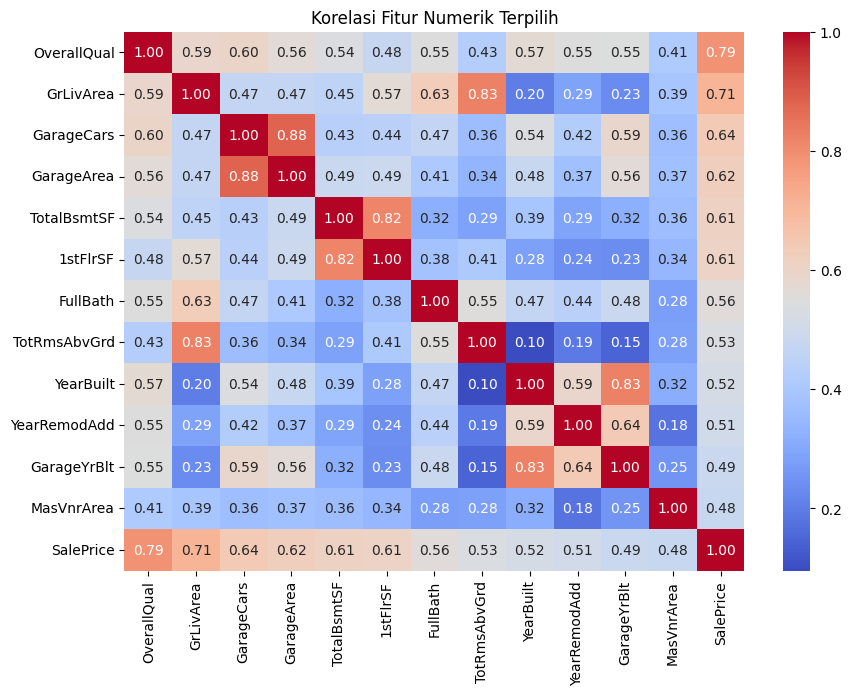

In [6]:
# Korelasi fitur numerik dengan SalePrice
numeric_corr = train.select_dtypes(include=np.number).corr()["SalePrice"].drop("SalePrice")
top_corr = numeric_corr.abs().sort_values(ascending=False).head(12).index

plt.figure(figsize=(10, 7))
sns.heatmap(train[list(top_corr) + ["SalePrice"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi Fitur Numerik Terpilih")
plt.show()


**Penjelasan:**
- `select_dtypes(include=np.number)` memilih kolom numerik.
- `corr()` menghitung korelasi antar kolom numerik.
- Korelasi dengan `SalePrice` dipilih, lalu `abs()` melihat kekuatan korelasi tanpa membedakan arah positif atau negatif.
- `head(12)` mengambil 12 fitur dengan korelasi absolut tertinggi.
- `heatmap()` menyajikan nilai korelasi dalam bentuk warna dan angka.

Korelasi menunjukkan hubungan linear, bukan bukti sebab-akibat. Korelasi juga hanya dihitung untuk fitur numerik pada visualisasi ini.


## 4. Feature Preparation dan Preprocessing

Target (`y`) adalah kolom yang ingin diprediksi, yaitu `SalePrice`. Fitur (`X`) adalah kolom input selain target dan `Id`. Kolom `Id` dikeluarkan karena hanya berfungsi sebagai identitas baris, bukan karakteristik rumah yang bermakna untuk prediksi.

Data dibagi menjadi 80% training dan 20% validasi. Preprocessing dibuat dalam pipeline agar proses imputasi dan encoding dipelajari dari training saja, sehingga mengurangi risiko data leakage.


In [7]:
X = train.drop(columns=["SalePrice", "Id"])
y = train["SalePrice"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Jumlah fitur numerik:", len(numeric_features))
print("Jumlah fitur kategorikal:", len(categorical_features))
print("Data train:", X_train.shape, "| Data validasi:", X_valid.shape)


Jumlah fitur numerik: 36
Jumlah fitur kategorikal: 43
Data train: (1168, 79) | Data validasi: (292, 79)


**Penjelasan kode:**
- `drop()` mengeluarkan kolom target dan ID dari fitur input.
- `train_test_split(..., test_size=0.20)` menyisihkan 20% baris untuk validasi.
- `select_dtypes()` memisahkan fitur numerik dan kategorikal.
- Imputer numerik memakai `median` (nilai tengah), lebih tahan terhadap nilai ekstrem dibanding rata-rata.
- Imputer kategorikal memakai `most_frequent` (kategori paling sering).
- `OneHotEncoder(handle_unknown="ignore")` membuat kolom indikator untuk kategori dan tidak error jika kategori baru muncul pada validasi/test.
- `ColumnTransformer` menerapkan pipeline numerik ke kolom numerik dan pipeline kategorikal ke kolom kategori.

**Mengapa pipeline penting?** Seluruh proses yang “belajar” dari data dilakukan setelah pembagian data. Ini menjaga validasi tetap menjadi data yang belum dilihat saat pelatihan.


## 5. Modeling — Melatih dan Membandingkan Model

Tiga algoritma dicoba pada split yang sama:
1. **Linear Regression**: model linear sebagai baseline.
2. **Random Forest Regressor**: gabungan banyak pohon keputusan; hasil prediksi dirata-ratakan.
3. **Extra Trees Regressor**: gabungan pohon dengan pemilihan split yang lebih acak.

Setiap algoritma digabung dengan preprocessing menggunakan `Pipeline`.


In [8]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    )
}

fitted_models = {}
predictions = {}
rows = []

for name, estimator in models.items():
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_valid)

    fitted_models[name] = model_pipeline
    predictions[name] = y_pred
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_valid, y_pred),
        "RMSE": mean_squared_error(y_valid, y_pred) ** 0.5,
        "R2": r2_score(y_valid, y_pred)
    })

evaluation = pd.DataFrame(rows).sort_values("RMSE")
display(evaluation)


,Model,MAE,RMSE,R2
2,Extra Trees,17445.841815,27901.362756,0.898507
1,Random Forest,17350.759064,28376.645804,0.895020
0,Linear Regression,20466.133696,31294.990974,0.872316


**Penjelasan kode:**
- `models` menyimpan algoritma yang akan diuji.
- `n_estimators=300` berarti Random Forest dan Extra Trees membangun 300 pohon.
- `n_jobs=-1` memakai seluruh core CPU yang tersedia untuk proses paralel.
- `Pipeline([...])` menjalankan preprocessing terlebih dahulu lalu model.
- `fit(X_train, y_train)` melatih model menggunakan data training.
- `predict(X_valid)` menghasilkan prediksi harga pada data validasi.
- Prediksi dan model tersimpan dalam dictionary agar bisa dianalisis kembali.
- `evaluation` menyimpan metrik dari tiap model dan diurutkan berdasarkan RMSE terendah.


## 6. Evaluation — Mengevaluasi Performa

Metrik yang digunakan:
- **MAE (Mean Absolute Error):** rata-rata selisih absolut antara harga aktual dan prediksi. Semakin kecil semakin baik.
- **RMSE (Root Mean Squared Error):** akar rata-rata kuadrat kesalahan. Lebih memberi penalti pada kesalahan besar. Semakin kecil semakin baik.
- **R² (Coefficient of Determination):** ukuran seberapa besar variasi target yang dapat dijelaskan model. Nilai mendekati 1 umumnya lebih baik; dapat bernilai negatif jika model buruk.


### Dasar Referensi Pemilihan Metrik Evaluasi

Evaluasi kinerja model machine learning untuk tugas regresi dapat dilakukan menggunakan metrik Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), dan koefisien determinasi (𝑅2). Polverino et al. (2023) menjelaskan bahwa MSE, RMSE, dan MAE memiliki rentang nilai 0 hingga tak hingga, sehingga semakin kecil nilai RMSE dan MAE, semakin tinggi akurasi prediksi model; sebaliknya, nilai 𝑅2

 semakin baik apabila mendekati 1 karena menunjukkan kemampuan model dalam menjelaskan variasi data (Polverino et al., 2023). RMSE lebih sensitif terhadap outlier karena kesalahan prediksi dikuadratkan, sehingga kesalahan besar memberikan pengaruh lebih besar terhadap nilai RMSE, sedangkan MAE mengukur rata-rata besar kesalahan absolut antara nilai aktual dan nilai prediksi sehingga lebih robust terhadap outlier (Polverino et al., 2023). Oleh karena itu, RMSE lebih tepat digunakan apabila kesalahan besar atau outlier perlu diperhatikan, sedangkan MAE lebih tepat digunakan apabila ingin memperoleh ukuran rata-rata kesalahan yang lebih stabil. Hal ini sejalan dengan Hendra, Erawadi, dan Leni (2023), yang menunjukkan bahwa nilai MAE dan RMSE yang kecil atau mendekati nol mengindikasikan hasil prediksi mampu mewakili data aktual dengan baik. Dengan demikian, model machine learning dikatakan lebih baik apabila memiliki nilai RMSE dan MAE yang lebih rendah serta nilai 𝑅2
 yang lebih tinggi (Asthana et al., 2023; Polverino et al., 2023).

**Referensi**

Asthana, P., Mishra, S., Gupta, N., Derawi, M., & Kumar, A. (2023). Prediction of student’s performance with learning coefficients using regression based machine learning models. IEEE Access, 11, 72732–72742. https://doi.org/10.1109/ACCESS.2023.3294700

Hendra, Erawadi, D., & Leni, D. (2023). Penerapan data sintetis dalam simulasi kinerja mesin pemipil jagung. Jurnal Rekayasa Material, Manufaktur dan Energi, 6(1), 119–127. https://doi.org/10.30596/rmme.v6i1.14219

Polverino, L., Abbate, R., Manco, P., Perfetto, D., Caputo, F., Macchiaroli, R., & Caterino, M. (2023). Machine learning for prognostics and health management of industrial mechanical systems and equipment: A systematic literature review. International Journal of Engineering Business Management, 14, 1–19. https://doi.org/10.1177/18479790231186848

Model terbaik berdasarkan RMSE: Extra Trees
MAE  : 17,445.84
RMSE : 27,901.36
R²   : 0.8985


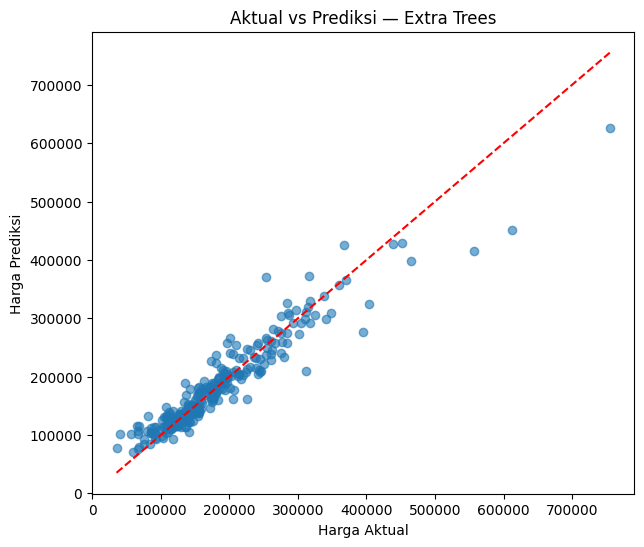

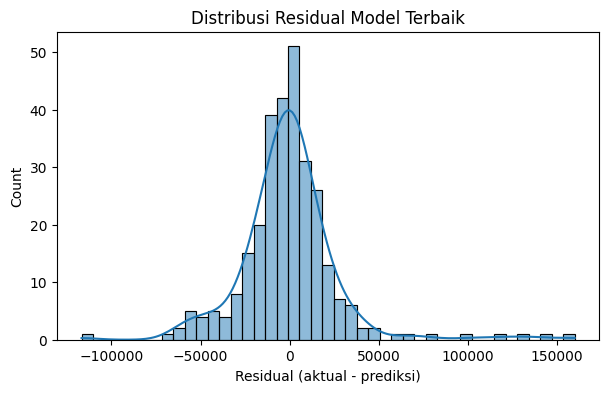

In [9]:
best_name = evaluation.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]

print("Model terbaik berdasarkan RMSE:", best_name)
print(f"MAE  : {mean_absolute_error(y_valid, best_pred):,.2f}")
print(f"RMSE : {mean_squared_error(y_valid, best_pred) ** 0.5:,.2f}")
print(f"R²   : {r2_score(y_valid, best_pred):.4f}")

plt.figure(figsize=(7, 6))
plt.scatter(y_valid, best_pred, alpha=0.6)
min_val = min(y_valid.min(), best_pred.min())
max_val = max(y_valid.max(), best_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Harga Aktual")
plt.ylabel("Harga Prediksi")
plt.title(f"Aktual vs Prediksi — {best_name}")
plt.show()

residuals = y_valid - best_pred
plt.figure(figsize=(7, 4))
sns.histplot(residuals, kde=True)
plt.title("Distribusi Residual Model Terbaik")
plt.xlabel("Residual (aktual - prediksi)")
plt.show()


**Penjelasan grafik evaluasi:**
- Model dipilih dengan mengambil baris pertama dari tabel yang sudah diurutkan menurut RMSE.
- Pada grafik aktual vs prediksi, garis diagonal merah merupakan prediksi ideal. Titik yang dekat dengan garis berarti prediksi mendekati harga aktual.
- Residual adalah `harga aktual - harga prediksi`.
- Histogram residual menunjukkan sebaran kesalahan. Residual di sekitar nol menandakan prediksi yang cenderung tidak terlalu jauh, tetapi pola dan pencilan tetap perlu diperiksa.


## 7. Prediksi pada `test.csv` (opsional)

Setelah evaluasi dan pemilihan model, model terbaik dilatih ulang menggunakan seluruh baris berlabel di `train.csv`. Model tersebut lalu memprediksi harga untuk `test.csv`.

Prediksi pada test tidak dapat dievaluasi dengan MAE/RMSE/R² karena file tersebut tidak menyediakan harga aktual.


In [10]:
X_all = train.drop(columns=["SalePrice", "Id"])
y_all = train["SalePrice"]
X_test = test.drop(columns=["Id"], errors="ignore")

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", models[best_name])
])
final_model.fit(X_all, y_all)
test_predictions = final_model.predict(X_test)

submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})
display(submission.head())

# Simpan hasil prediksi jika diperlukan:
# submission.to_csv("house_price_predictions.csv", index=False)


,Id,SalePrice
0,1461,118132.776667
1,1462,149203.833333
2,1463,172945.966667
3,1464,188513.333333
4,1465,191251.630000


**Penjelasan:**
- `X_all` dan `y_all` mengambil seluruh data berlabel.
- `X_test` menyiapkan fitur pada data test; kolom `Id` tidak dipakai sebagai input model.
- `fit()` melatih ulang model terbaik menggunakan seluruh train.
- `predict()` menghasilkan perkiraan harga untuk setiap baris test.
- `submission` menyusun hasil dengan kolom `Id` dan `SalePrice`.
- Baris `to_csv()` dapat diaktifkan untuk menyimpan hasil prediksi ke file CSV.

## Ringkasan Alur
Data Loading → Data Understanding → Data Cleaning/EDA → Preprocessing → Training Model → Evaluasi → Prediksi Test.

**Catatan interpretasi:** nilai metrik bergantung pada pembagian data dan parameter model. Hasil validasi adalah estimasi performa; evaluasi yang lebih kuat dapat dilakukan dengan cross-validation dan tuning parameter.
